# Árboles de Decisión: Teoría Completa

**Machine Learning 1 — FIUNA**

**Docente:** Diego Stalder | **Práctica:** Carlos Benítez

---

## Descripción

Los **Árboles de Decisión** son uno de los algoritmos más intuitivos y poderosos del Machine Learning. Esta clase teórica presenta los fundamentos matemáticos completos, desde la definición de impureza hasta la poda por complejidad de costo.

## Estructura

1. **Intuición geométrica** — particiones recursivas del espacio
2. **Métricas de impureza** — Gini, Entropía, Error de clasificación (con derivaciones)
3. **Ganancia de información** — criterio de división óptimo
4. **Algoritmo CART** — construcción greedy y criterios de parada
5. **Poda** — pre-poda y post-poda por complejidad de costo
6. **Árboles de regresión** — varianza como impureza
7. **Interpretación** — importancia de características y reglas
8. **Referencias bibliográficas**

## Referencias principales

- **Breiman, L., Friedman, J., Stone, C. J., & Olshen, R. A. (1984).** *Classification and Regression Trees*. CRC Press. [El paper fundacional de CART]
- **Quinlan, J. R. (1986).** *Induction of Decision Trees*. Machine Learning, 1(1), 81-106. [Introduce ID3 con entropía]
- **Quinlan, J. R. (1993).** *C4.5: Programs for Machine Learning*. Morgan Kaufmann. [Extensión de ID3]
- **Hastie, T., Tibshirani, R., & Friedman, J. (2009).** *The Elements of Statistical Learning* (2nd ed.). Springer. Capítulo 9. [Referencia teórica moderna]
- **Bishop, C. M. (2006).** *Pattern Recognition and Machine Learning*. Springer. Capítulo 14. [Fundamentos probabilísticos]
- **Scikit-learn Developers (2024).** *Decision Trees*. Documentación oficial.

## 0. Importaciones y Configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SymPy para derivaciones simbólicas
import sympy as sp
from sympy import symbols, log, diff, simplify, solve, Rational, exp, latex, init_printing, Symbol, oo

# Scikit-learn
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.datasets import make_moons, load_iris
from sklearn.model_selection import train_test_split

# Configuración de SymPy
init_printing(use_latex='mathjax')

# Configuración visual
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 11,
    'axes.grid': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 100
})
sns.set_palette('husl')
np.random.seed(42)

print("="*80)
print("🌳 ÁRBOLES DE DECISIÓN — Clase Teórica Completa")
print("="*80)
print(f"SymPy versión: {sp.__version__}")

🌳 ÁRBOLES DE DECISIÓN — Clase Teórica Completa
SymPy versión: 1.13.1


---
# Parte 1: Intuición Geométrica

## 1.1 Definición formal de un Árbol de Decisión

Un **Árbol de Decisión** es un modelo $f: \mathcal{X} \to \mathcal{Y}$ que se define recursivamente:

$$f(\mathbf{x}) = \begin{cases}
c_t & \text{si } t \text{ es una hoja} \\
f(\mathbf{x}_{\text{izq}}) & \text{si } x_j \le s \text{ en el nodo interno } t \\
f(\mathbf{x}_{\text{der}}) & \text{si } x_j > s \text{ en el nodo interno } t
\end{cases}$$

donde:
- $c_t \in \mathcal{Y}$ es la clase predicha en la hoja $t$
- $j$ es el índice de la característica usada para dividir
- $s \in \mathbb{R}$ es el umbral de división

## 1.2 Partición del espacio

Un árbol divide el espacio de características en **regiones rectangulares disjuntas** mediante divisiones paralelas a los ejes:

$$\mathcal{X} = \bigcup_{t \in \text{hojas}} R_t, \quad R_t \cap R_{t'} = \emptyset \text{ si } t \neq t'$$

Cada región $R_t$ se define por la conjunción de las condiciones a lo largo del camino desde la raíz hasta $t$:

$$R_t = \{\mathbf{x} \in \mathcal{X} : \bigwedge_{v \in \text{camino}(\text{raíz}, t)} (x_{j_v} \le s_v \text{ ó } x_{j_v} > s_v)\}$$

## 1.3 Visualización

La frontera de decisión es **ortogonal** — formada por segmentos paralelos a los ejes coordenados.

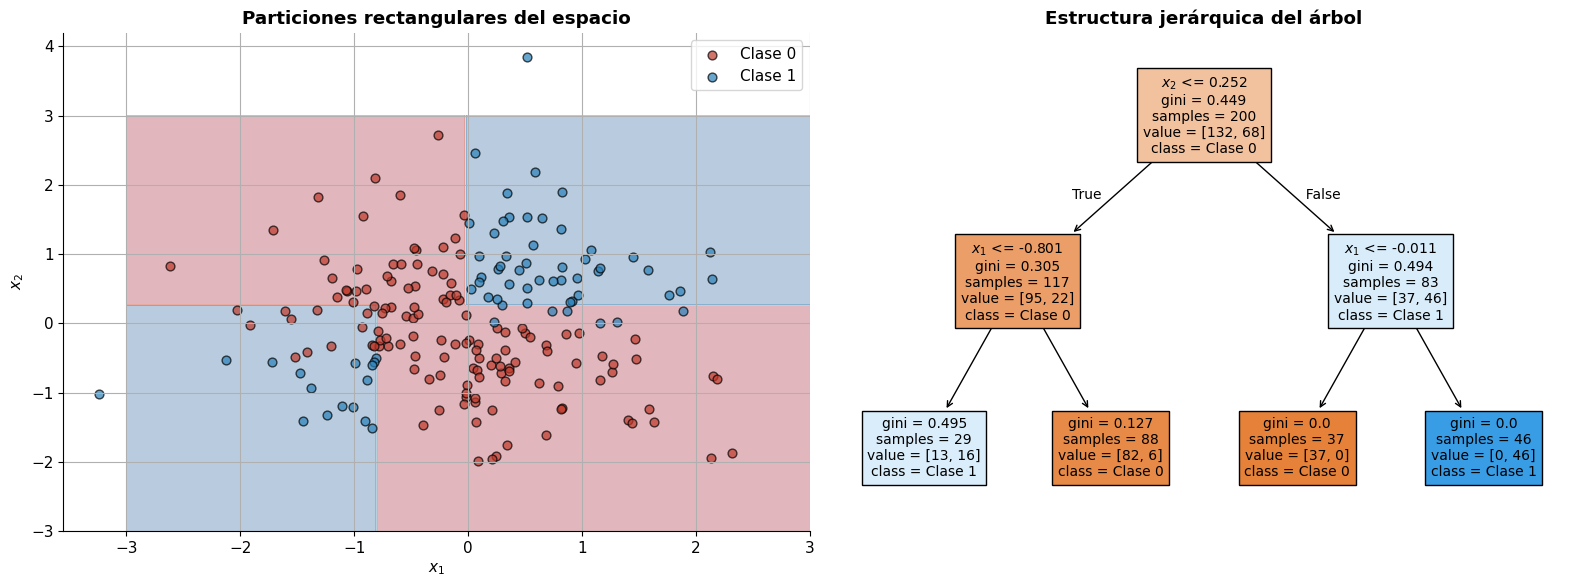

🌳 Observaciones:
   1. Cada nodo interno hace una pregunta sobre UNA característica
   2. La frontera resultante es un conjunto de rectángulos
   3. A mayor profundidad, más rectángulos y fronteras más complejas


In [2]:
# Visualización: particiones rectangulares del espacio 2D
np.random.seed(42)
X_demo = np.random.randn(200, 2)
y_demo = ((X_demo[:, 0] > 0) & (X_demo[:, 1] > 0)).astype(int)
y_demo = y_demo ^ ((X_demo[:, 0] < -0.5) & (X_demo[:, 1] < -0.5)).astype(int)

tree_demo = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_demo.fit(X_demo, y_demo)

xx, yy = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
Z = tree_demo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].contourf(xx, yy, Z, alpha=0.3, cmap='RdBu')
axes[0].scatter(X_demo[y_demo==0, 0], X_demo[y_demo==0, 1],
                c='#C0392B', s=40, edgecolor='k', alpha=0.7, label='Clase 0')
axes[0].scatter(X_demo[y_demo==1, 0], X_demo[y_demo==1, 1],
                c='#2980B9', s=40, edgecolor='k', alpha=0.7, label='Clase 1')
axes[0].set_title('Particiones rectangulares del espacio', fontweight='bold')
axes[0].set_xlabel('$x_1$'); axes[0].set_ylabel('$x_2$')
axes[0].legend()

plot_tree(tree_demo, filled=True, feature_names=['$x_1$', '$x_2$'],
          class_names=['Clase 0', 'Clase 1'], ax=axes[1], fontsize=10)
axes[1].set_title('Estructura jerárquica del árbol', fontweight='bold')

plt.tight_layout()
plt.show()

print("🌳 Observaciones:")
print("   1. Cada nodo interno hace una pregunta sobre UNA característica")
print("   2. La frontera resultante es un conjunto de rectángulos")
print("   3. A mayor profundidad, más rectángulos y fronteras más complejas")

---
# Parte 2: Métricas de Impureza

## 2.1 Formalización

Sea un nodo $t$ con $n_t$ ejemplos. Definimos $p_k^{(t)}$ como la **proporción** de ejemplos de la clase $k$ en el nodo $t$:

$$p_k^{(t)} = \frac{|\{(\mathbf{x}_i, y_i) \in t : y_i = k\}|}{n_t}, \quad \sum_{k=1}^{K} p_k^{(t)} = 1$$

Una **función de impureza** $I(t)$ mide el grado de mezcla de clases en el nodo $t$. Debe satisfacer tres propiedades:

1. **Simetría:** $I(t)$ es invariante a permutaciones de las clases
2. **Máximo en distribución uniforme:** $I(t) \le I_{\max}$, con igualdad si $p_k = 1/K$ para todo $k$
3. **Mínimo en pureza:** $I(t) = 0$ si $\exists k : p_k = 1$

## 2.2 Índice de Gini

### Definición

$$\boxed{\text{Gini}(t) = 1 - \sum_{k=1}^{K} (p_k^{(t)})^2 = \sum_{k=1}^{K} p_k^{(t)} (1 - p_k^{(t)})}$$

### Interpretación probabilística

Consideremos dos ejemplos seleccionados **independientemente al azar** del nodo $t$. La probabilidad de que sean de la **misma clase** es $\sum_k p_k^2$. Por lo tanto, la probabilidad de que sean de **clases distintas** es:

$$\text{Gini}(t) = P(\text{clases distintas}) = 1 - \sum_k p_k^2$$

**Interpretación:** el Gini mide la probabilidad de **clasificación incorrecta** si se etiqueta cada ejemplo según la distribución del nodo. Es equivalente al **error de Bayes** para clasificación aleatoria.

In [3]:
# Verificación simbólica del máximo del Gini
print("="*80)
print("🔬 VERIFICACIÓN SIMBÓLICA: MÁXIMO DEL GINI")
print("="*80)

p1, p2 = symbols('p_1 p_2', positive=True)

# Gini binario: 1 - p1^2 - p2^2 con p2 = 1 - p1
p = Symbol('p', positive=True)
gini_p = 1 - p**2 - (1 - p)**2
gini_simplified = sp.expand(gini_p)

print("\nGini binario como función de p:")
display(sp.Eq(Symbol('G(p)'), gini_simplified))

# Derivada
gini_deriv = diff(gini_simplified, p)
print("\nDerivada:")
display(sp.Eq(Symbol('G\'(p)'), gini_deriv))

# Punto crítico
p_critico = solve(gini_deriv, p)
print(f"\nPunto crítico: p = {p_critico}")

# Verificar que es máximo (segunda derivada negativa)
gini_second = diff(gini_simplified, p, 2)
print(f"\nSegunda derivada: {gini_second} < 0 → máximo confirmado")

# Valor máximo
gini_max = gini_simplified.subs(p, Rational(1, 2))
print(f"\nValor máximo de Gini: G(1/2) = {gini_max}")

# Generalización a K clases
print("\n" + "="*80)
print("Generalización a K clases equiprobables (p_k = 1/K):")
print("="*80)
K = Symbol('K', positive=True, integer=True)
gini_K = 1 - K * (1/K)**2
print("Gini_max = 1 - K·(1/K)² = 1 - 1/K")
display(sp.simplify(gini_K))
print("\n→ Para K=2: Gini_max = 1/2")
print("→ Para K=3: Gini_max = 2/3")
print("→ A medida que K crece, el Gini máximo se aproxima a 1")

🔬 VERIFICACIÓN SIMBÓLICA: MÁXIMO DEL GINI

Gini binario como función de p:


            2      
G(p) = - 2⋅p  + 2⋅p


Derivada:


G'(p) = 2 - 4⋅p


Punto crítico: p = [1/2]

Segunda derivada: -4 < 0 → máximo confirmado

Valor máximo de Gini: G(1/2) = 1/2

Generalización a K clases equiprobables (p_k = 1/K):
Gini_max = 1 - K·(1/K)² = 1 - 1/K


K - 1
─────
  K  


→ Para K=2: Gini_max = 1/2
→ Para K=3: Gini_max = 2/3
→ A medida que K crece, el Gini máximo se aproxima a 1


## 2.3 Entropía

### Definición

$$\boxed{H(t) = -\sum_{k=1}^{K} p_k^{(t)} \log_2(p_k^{(t)})}$$

### Fundamentos teóricos (Shannon, 1948)

La entropía mide la **cantidad esperada de información** (en bits) necesaria para codificar la clase de un ejemplo seleccionado al azar del nodo $t$. Es el número promedio mínimo de bits necesarios para transmitir la clase.

### Propiedades

1. **Continuidad:** $H(t)$ es continua en $p_k$
2. **Simetría:** $H$ es invariante a permutaciones
3. **Máximo en uniformidad:** $H_{\max} = \log_2 K$
4. **Mínimo en pureza:** $H = 0$ si $\exists k : p_k = 1$
5. **Concavidad:** $H$ es cóncava en el símplex de probabilidades

### Convención

Se define $0 \log_2 0 = 0$ por continuidad, ya que $\lim_{p \to 0^+} p \log_2 p = 0$.

In [4]:
# Verificación simbólica del máximo de la Entropía
print("="*80)
print("🔬 VERIFICACIÓN SIMBÓLICA: MÁXIMO DE LA ENTROPÍA")
print("="*80)

p = Symbol('p', positive=True)

# Entropía binaria
H_p = -p * log(p, 2) - (1 - p) * log(1 - p, 2)

print("\nEntropía binaria:")
display(sp.Eq(Symbol('H(p)'), H_p))

# Derivada
H_deriv = sp.simplify(diff(H_p, p))
print("\nDerivada (usando cambio de base log₂(x) = ln(x)/ln(2)):")
display(sp.Eq(Symbol('H\'(p)'), H_deriv))

# Punto crítico
p_critico_H = solve(H_deriv, p)
print(f"\nPunto crítico: p = {p_critico_H}")

# Verificar máximo con segunda derivada
H_second = sp.simplify(diff(H_p, p, 2))
print(f"\nSegunda derivada evaluada en p=1/2: {H_second.subs(p, Rational(1,2)):.4f}")
print("(Negativa → máximo confirmado)")

# Valor máximo
H_max = sp.simplify(H_p.subs(p, Rational(1, 2)))
print(f"\nValor máximo de Entropía: H(1/2) = {H_max} = 1 bit")

🔬 VERIFICACIÓN SIMBÓLICA: MÁXIMO DE LA ENTROPÍA

Entropía binaria:


         p⋅log(p)   (1 - p)⋅log(1 - p)
H(p) = - ──────── - ──────────────────
          log(2)          log(2)      


Derivada (usando cambio de base log₂(x) = ln(x)/ln(2)):


           ⎛1 - p⎞
        log⎜─────⎟
           ⎝  p  ⎠
H'(p) = ──────────
          log(2)  


Punto crítico: p = [1/2]

Segunda derivada evaluada en p=1/2: -5.7708
(Negativa → máximo confirmado)

Valor máximo de Entropía: H(1/2) = 1 = 1 bit


## 2.4 Error de Clasificación

### Definición

$$\boxed{E(t) = 1 - \max_{k} p_k^{(t)}}$$

### Interpretación

El error de clasificación mide la proporción de ejemplos que serían **mal clasificados** si asignamos a todos los ejemplos del nodo la clase mayoritaria (regla de Bayes óptima para error 0-1).

### Comparación con Gini y Entropía

| Métrica | Ventajas | Desventajas |
|---------|----------|-------------|
| **Gini** | Suave, diferenciable, rápida | Menos sensible a cambios |
| **Entropía** | Base teórica sólida (Shannon) | Más costosa computacionalmente ($\log$) |
| **Error clasif.** | Simple, interpretable | No suave, poco sensible en árboles profundos |

En la práctica, **Gini y Entropía** producen árboles muy similares. Gini es el criterio por defecto en scikit-learn por su eficiencia computacional.

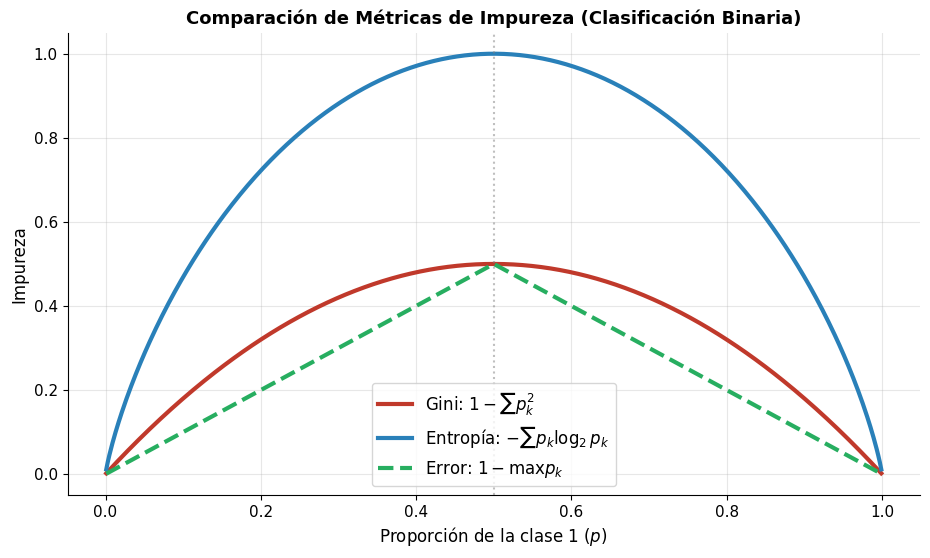

📊 Valores en el máximo (p=0.5):
   Gini:              0.5000
   Entropía:          1.0000 bits
   Error clasif.:     0.5000

→ El error de clasificación es MENOS sensible a cambios
→ El error de clasificación es LINEAL a trozos (no suave)


In [5]:
# Visualización comparativa de las tres métricas
p = np.linspace(0.001, 0.999, 500)

gini = 1 - (p**2 + (1-p)**2)
entropia = -p * np.log2(p) - (1-p) * np.log2(1-p)
error_clas = 1 - np.maximum(p, 1-p)

plt.figure(figsize=(11, 6))
plt.plot(p, gini, linewidth=3, label='Gini: $1 - \\sum p_k^2$', color='#C0392B')
plt.plot(p, entropia, linewidth=3, label='Entropía: $-\\sum p_k \\log_2 p_k$', color='#2980B9')
plt.plot(p, error_clas, linewidth=3, linestyle='--', label='Error: $1 - \\max p_k$', color='#27AE60')
plt.axvline(x=0.5, color='gray', linestyle=':', alpha=0.5)
plt.xlabel('Proporción de la clase 1 ($p$)', fontsize=12)
plt.ylabel('Impureza', fontsize=12)
plt.title('Comparación de Métricas de Impureza (Clasificación Binaria)', fontweight='bold', fontsize=13)
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.show()

print("📊 Valores en el máximo (p=0.5):")
print(f"   Gini:              {1 - (0.5**2 + 0.5**2):.4f}")
print(f"   Entropía:          {-2 * 0.5 * np.log2(0.5):.4f} bits")
print(f"   Error clasif.:     {1 - 0.5:.4f}")
print("\n→ El error de clasificación es MENOS sensible a cambios")
print("→ El error de clasificación es LINEAL a trozos (no suave)")

---
# Parte 3: Ganancia de Información

## 3.1 Definición

Sea $D$ un conjunto de ejemplos y $A$ una característica con valores $\{a_1, \ldots, a_V\}$. Al dividir $D$ por $A$, obtenemos $V$ subconjuntos $D_1, \ldots, D_V$.

La **Ganancia de Información** es:

$$\boxed{\text{Gain}(D, A) = I(D) - \sum_{v=1}^{V} \frac{|D_v|}{|D|} \cdot I(D_v)}$$

donde $I(\cdot)$ es la métrica de impureza (Gini o Entropía).

## 3.2 Interpretación

- $I(D)$: impureza del nodo padre **antes** de dividir
- $\sum_v \frac{|D_v|}{|D|} I(D_v)$: impureza **promedio ponderada** de los hijos **después** de dividir
- **Gain**: reducción de impureza producida por la división

## 3.3 Ratio de Ganancia (C4.5)

Quinlan (1993) propuso el **Gain Ratio** para penalizar características con muchos valores (que producen muchas divisiones):

$$\text{GainRatio}(D, A) = \frac{\text{Gain}(D, A)}{\text{SplitInfo}(D, A)}$$

donde:

$$\text{SplitInfo}(D, A) = -\sum_{v=1}^{V} \frac{|D_v|}{|D|} \log_2 \frac{|D_v|}{|D|}$$

**Motivación:** características con muchos valores únicos (como RUT de estudiante) tienen SplitInfo alto y son penalizadas.

## 3.4 Ejemplo Numérico Original: Predicción Académica

**Escenario:** 10 estudiantes con 3 características para predecir si aprueban Cálculo 2.

| Estudiante | Parcial 1 | Asistencia | TP-Lab | Aprobó C2 |
|-----------|-----------|------------|--------|-----------|
| E1 | Alto | Alta | Alto | Sí |
| E2 | Alto | Alta | Bajo | Sí |
| E3 | Alto | Baja | Alto | Sí |
| E4 | Bajo | Alta | Alto | Sí |
| E5 | Bajo | Baja | Alto | No |
| E6 | Bajo | Baja | Bajo | No |
| E7 | Alto | Baja | Bajo | Sí |
| E8 | Bajo | Alta | Bajo | No |
| E9 | Alto | Alta | Alto | Sí |
| E10 | Bajo | Baja | Bajo | No |

In [6]:
# Dataset académico
datos = pd.DataFrame({
    'Estudiante': ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10'],
    'Parcial1':   ['Alto', 'Alto', 'Alto', 'Bajo', 'Bajo', 'Bajo', 'Alto', 'Bajo', 'Alto', 'Bajo'],
    'Asistencia': ['Alta', 'Alta', 'Baja', 'Alta', 'Baja', 'Baja', 'Baja', 'Alta', 'Alta', 'Baja'],
    'TPLab':      ['Alto', 'Bajo', 'Alto', 'Alto', 'Alto', 'Bajo', 'Bajo', 'Bajo', 'Alto', 'Bajo'],
    'Aprobó':     ['Sí', 'Sí', 'Sí', 'Sí', 'No', 'No', 'Sí', 'No', 'Sí', 'No']
})

print("="*80)
print("📊 DATASET: 10 ESTUDIANTES, 3 CARACTERÍSTICAS")
print("="*80)
print(datos.to_string(index=False))

n_si = (datos['Aprobó'] == 'Sí').sum()
n_no = (datos['Aprobó'] == 'No').sum()
n_total = len(datos)

p_si = n_si / n_total
p_no = n_no / n_total

print(f"\nDistribución en la raíz: Sí={n_si}, No={n_no}")
print(f"Proporciones: p(Sí)={p_si:.2f}, p(No)={p_no:.2f}")

gini_raiz = 1 - p_si**2 - p_no**2
entropia_raiz = -p_si * np.log2(p_si) - p_no * np.log2(p_no)

print(f"\nImpureza del nodo raíz:")
print(f"   Gini:      {gini_raiz:.4f}")
print(f"   Entropía:  {entropia_raiz:.4f} bits")

📊 DATASET: 10 ESTUDIANTES, 3 CARACTERÍSTICAS
Estudiante Parcial1 Asistencia TPLab Aprobó
        E1     Alto       Alta  Alto     Sí
        E2     Alto       Alta  Bajo     Sí
        E3     Alto       Baja  Alto     Sí
        E4     Bajo       Alta  Alto     Sí
        E5     Bajo       Baja  Alto     No
        E6     Bajo       Baja  Bajo     No
        E7     Alto       Baja  Bajo     Sí
        E8     Bajo       Alta  Bajo     No
        E9     Alto       Alta  Alto     Sí
       E10     Bajo       Baja  Bajo     No

Distribución en la raíz: Sí=6, No=4
Proporciones: p(Sí)=0.60, p(No)=0.40

Impureza del nodo raíz:
   Gini:      0.4800
   Entropía:  0.9710 bits


In [7]:
# Cálculo de la ganancia de información por característica
def gini(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p**2)

def entropia(y):
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return -np.sum(p * np.log2(p))

def ganancia(X, y, feature, metrica='gini'):
    imp_padre = gini(y) if metrica == 'gini' else entropia(y)
    n_total = len(y)
    imp_prom = 0
    for v in X[feature].unique():
        y_sub = y[X[feature] == v]
        imp_sub = gini(y_sub) if metrica == 'gini' else entropia(y_sub)
        imp_prom += (len(y_sub) / n_total) * imp_sub
    return imp_padre - imp_prom

X_demo = datos[['Parcial1', 'Asistencia', 'TPLab']]
y_demo = datos['Aprobó']

print("="*80)
print("📊 GANANCIA DE INFORMACIÓN POR CARACTERÍSTICA")
print("="*80)
print(f"\n{'Característica':<15} | {'Ganancia (Gini)':<15} | {'Ganancia (Entropía)':<18}")
print("-" * 55)

for feat in ['Parcial1', 'Asistencia', 'TPLab']:
    g_gini = ganancia(X_demo, y_demo, feat, 'gini')
    g_ent = ganancia(X_demo, y_demo, feat, 'entropia')
    print(f"{feat:<15} | {g_gini:<15.4f} | {g_ent:<18.4f}")

print(f"\n💡 Ambas métricas coinciden: 'Parcial1' es la mejor característica para dividir")

📊 GANANCIA DE INFORMACIÓN POR CARACTERÍSTICA

Característica  | Ganancia (Gini) | Ganancia (Entropía)
-------------------------------------------------------
Parcial1        | 0.3200          | 0.6100            
Asistencia      | 0.0800          | 0.1245            
TPLab           | 0.0800          | 0.1245            

💡 Ambas métricas coinciden: 'Parcial1' es la mejor característica para dividir


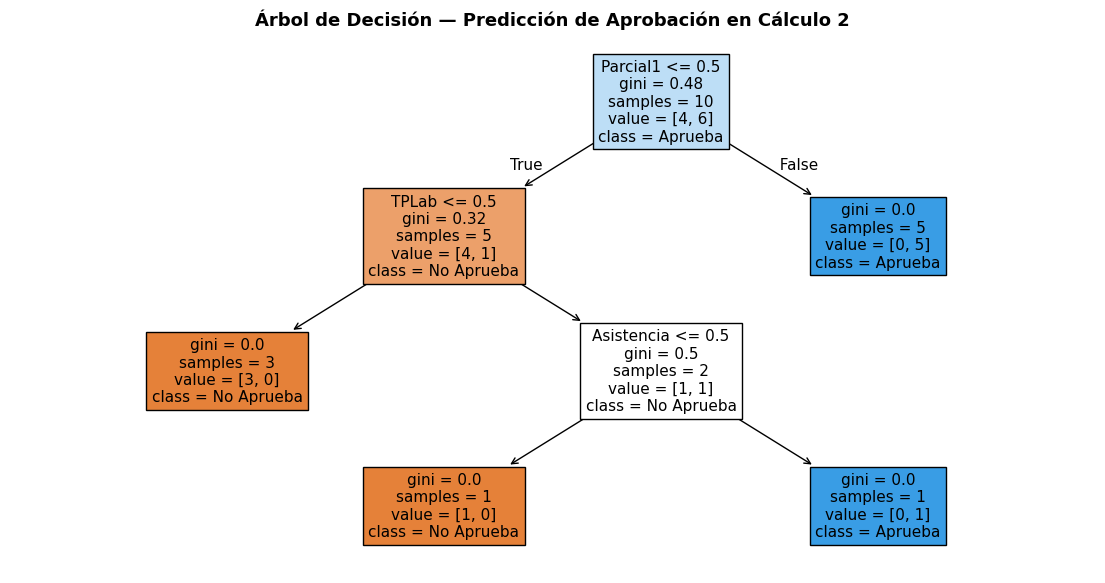


📋 REGLAS DE DECISIÓN EXTRAÍDAS
|--- Parcial1 <= 0.50
|   |--- TPLab <= 0.50
|   |   |--- class: 0
|   |--- TPLab >  0.50
|   |   |--- Asistencia <= 0.50
|   |   |   |--- class: 0
|   |   |--- Asistencia >  0.50
|   |   |   |--- class: 1
|--- Parcial1 >  0.50
|   |--- class: 1



In [8]:
# Aplicar árbol al dataset académico
datos_enc = datos.copy()
for col in ['Parcial1', 'Asistencia', 'TPLab', 'Aprobó']:
    datos_enc[col] = datos_enc[col].map({'Alto': 1, 'Baja': 0, 'Alta': 1, 'Bajo': 0, 'Sí': 1, 'No': 0})

X_acad = datos_enc[['Parcial1', 'Asistencia', 'TPLab']]
y_acad = datos_enc['Aprobó']

tree_acad = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
tree_acad.fit(X_acad, y_acad)

plt.figure(figsize=(14, 7))
plot_tree(tree_acad, filled=True, feature_names=['Parcial1', 'Asistencia', 'TPLab'],
          class_names=['No Aprueba', 'Aprueba'], fontsize=11)
plt.title('Árbol de Decisión — Predicción de Aprobación en Cálculo 2', fontweight='bold', fontsize=13)
plt.show()

print("\n" + "="*80)
print("📋 REGLAS DE DECISIÓN EXTRAÍDAS")
print("="*80)
print(export_text(tree_acad, feature_names=['Parcial1', 'Asistencia', 'TPLab']))

---
# Parte 4: Algoritmo CART

## 4.1 Formulación matemática

El algoritmo CART (Breiman et al., 1984) busca construir un árbol que minimice una **función de costo global**:

$$\mathcal{L}(T) = \sum_{t \in \text{hojas}} \sum_{i \in t} \mathbb{1}[y_i \neq \hat{y}_t]$$

Este problema es **NP-duro** (Hyafil & Rivest, 1976). Por lo tanto, CART usa una estrategia **greedy (voraz)**: en cada nodo elige la mejor división local.

## 4.2 Criterio de división local

En cada nodo $t$, CART busca la división $(j^*, s^*)$ que minimiza la impureza ponderada de los hijos:

$$(j^*, s^*) = \arg\min_{j, s} \left[ \frac{n_{\text{izq}}}{n_t} I(t_{\text{izq}}) + \frac{n_{\text{der}}}{n_t} I(t_{\text{der}}) \right]$$

donde:
- $n_{\text{izq}} = |\{i \in t : x_{ij} \le s\}|$
- $n_{\text{der}} = |\{i \in t : x_{ij} > s\}|$
- $t_{\text{izq}}, t_{\text{der}}$ son los nodos hijos

## 4.3 Algoritmo

```
Entrada: D = {(x_i, y_i)}_{i=1}^n
Parámetros: criterio de parada (max_depth, min_samples_split, etc.)

1. Inicializar árbol con nodo raíz conteniendo todos los datos
2. Mientras existan nodos expandibles:
   3. Para cada nodo t:
      a. Si criterio de parada se cumple → convertir en hoja con clase mayoritaria
      b. Para cada característica j y umbral s:
         - Dividir D_t en {x_j <= s} y {x_j > s}
         - Calcular impureza ponderada
      c. Elegir división (j*, s*) con menor impureza
      d. Aplicar división y crear nodos hijos
4. Retornar árbol construido
```

## 4.4 Complejidad computacional

En cada nodo:
- **Búsqueda de umbral:** $O(n_t \cdot d)$ para ordenar cada característica
- **Total para el árbol:** $O(n \log n \cdot d)$ en el caso balanceado

## 4.5 Criterios de parada comunes

| Parámetro | Descripción |
|-----------|-------------|
| `max_depth` | Profundidad máxima del árbol |
| `min_samples_split` | Mínimo de muestras para dividir un nodo |
| `min_samples_leaf` | Mínimo de muestras en una hoja |
| `max_features` | Máximo de características a considerar |
| `min_impurity_decrease` | Reducción mínima de impureza para dividir |

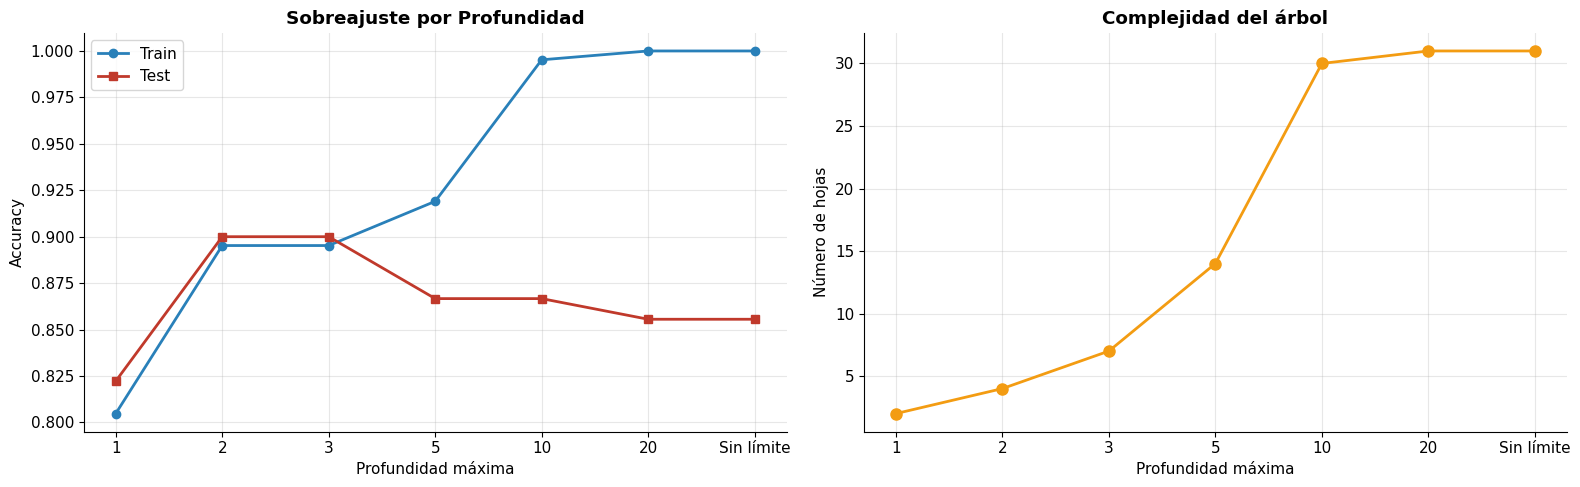

🌳 Observaciones:
   - Train accuracy siempre crece con profundidad (hasta 100%)
   - Test accuracy sube y luego baja (sobreajuste)
   - El punto óptimo suele estar en profundidad 3-7


In [9]:
# Demostración de sobreajuste por profundidad
np.random.seed(42)
X_moons, y_moons = make_moons(n_samples=300, noise=0.3, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

profundidades = [1, 2, 3, 5, 10, 20, None]
train_scores, test_scores, n_leaves = [], [], []

for d in profundidades:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree.fit(X_tr, y_tr)
    train_scores.append(tree.score(X_tr, y_tr))
    test_scores.append(tree.score(X_te, y_te))
    n_leaves.append(tree.get_n_leaves())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x_vals = range(len(profundidades))

axes[0].plot(x_vals, train_scores, 'o-', color='#2980B9', linewidth=2, label='Train')
axes[0].plot(x_vals, test_scores, 's-', color='#C0392B', linewidth=2, label='Test')
axes[0].set_xticks(x_vals)
axes[0].set_xticklabels([str(d) if d else 'Sin límite' for d in profundidades])
axes[0].set_xlabel('Profundidad máxima')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Sobreajuste por Profundidad', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(x_vals, n_leaves, 'o-', color='#F39C12', linewidth=2, markersize=8)
axes[1].set_xticks(x_vals)
axes[1].set_xticklabels([str(d) if d else 'Sin límite' for d in profundidades])
axes[1].set_xlabel('Profundidad máxima')
axes[1].set_ylabel('Número de hojas')
axes[1].set_title('Complejidad del árbol', fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("🌳 Observaciones:")
print("   - Train accuracy siempre crece con profundidad (hasta 100%)")
print("   - Test accuracy sube y luego baja (sobreajuste)")
print("   - El punto óptimo suele estar en profundidad 3-7")

---
# Parte 5: Poda (Pruning)

## 5.1 Motivación

Un árbol sin restricciones crece hasta que cada hoja es pura. Esto produce:
- **Alta varianza**: pequeños cambios en los datos alteran la estructura
- **Sobreajuste**: memoriza el ruido en lugar de aprender patrones
- **Baja interpretabilidad**: demasiadas reglas para analizar

**Solución:** la poda, que reduce el tamaño del árbol.

## 5.2 Pre-poda (Early Stopping)

Detiene el crecimiento del árbol durante la construcción. Criterios comunes:

1. **Profundidad máxima:** $\text{depth}(t) \ge d_{\max}$
2. **Mínimo de muestras:** $n_t < n_{\min}$
3. **Impureza mínima:** $I(t) < \epsilon$
4. **Reducción mínima de impureza:** $\Delta I < \delta$
5. **Máximo de hojas:** $|\text{hojas}| \ge L_{\max}$

**Ventaja:** computacionalmente eficiente (evita construir ramas inútiles).

**Desventaja:** puede detener el crecimiento demasiado pronto (efecto horizonte).

## 5.3 Post-poda: Cost Complexity Pruning (CCP)

Propuesta por Breiman et al. (1984). Construye el árbol completo y luego lo poda.

### Función de costo

$$\boxed{R_\alpha(T) = R(T) + \alpha \cdot |T|}$$

donde:
- $R(T) = \sum_{t \in \text{hojas}} \frac{n_t}{n} \cdot I(t)$: **error de clasificación ponderado** del árbol
- $|T|$: número de hojas del árbol
- $\alpha \ge 0$: **parámetro de complejidad** que penaliza árboles grandes

### Interpretación

- $\alpha = 0$: sin penalización → árbol completo
- $\alpha \to \infty$: penalización fuerte → árbol con solo la raíz
- Valores intermedios: trade-off entre precisión y simplicidad

### Algoritmo de poda débil más pequeña

1. Para cada nodo interno $t$, calcular:
   $$\alpha_t = \frac{R(t) - R(T_t)}{|T_t| - 1}$$
   donde $T_t$ es el subárbol con raíz $t$.
2. Poda el nodo con el menor $\alpha_t$ (el que menos "aporta").
3. Repetir hasta que solo quede la raíz.
4. Seleccionar el $\alpha$ óptimo mediante validación cruzada.

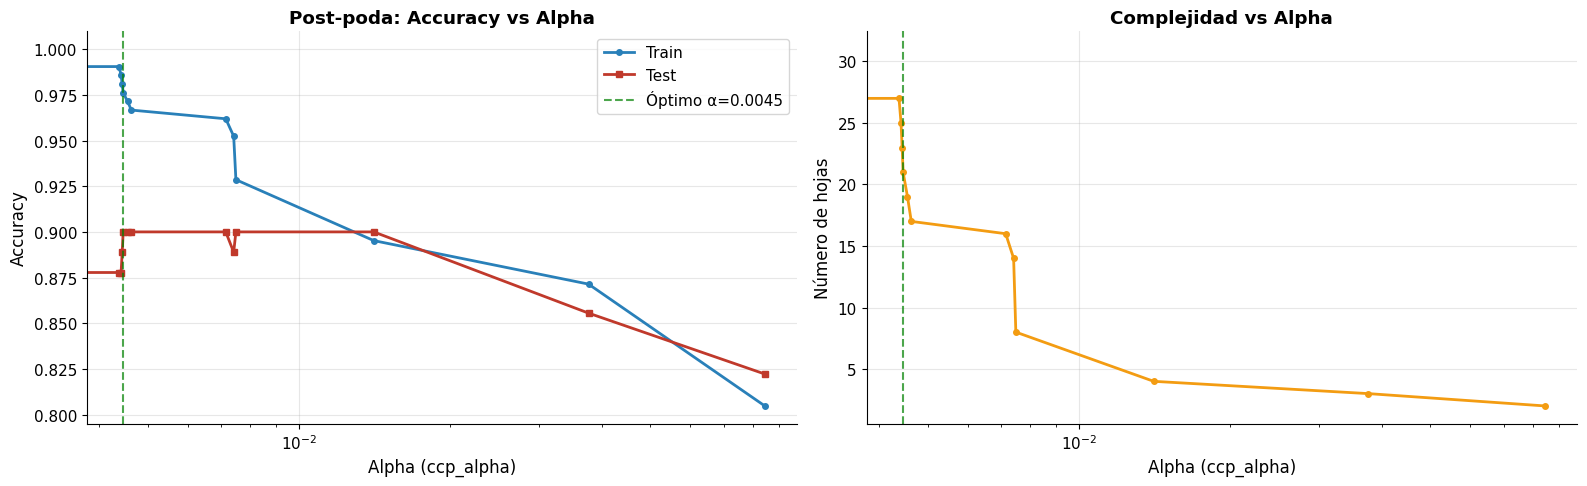

🌳 Mejor alpha: 0.004464
   Accuracy en test: 90.00%
   Hojas del árbol podado: 21
   Hojas del árbol completo: 31
   Reducción de complejidad: 32.3%


In [10]:
# Demostración de CCP: evolución de alpha y accuracy
np.random.seed(42)
X_moons, y_moons = make_moons(n_samples=300, noise=0.3, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X_moons, y_moons, test_size=0.3, random_state=42)

# Obtener la ruta de poda
tree_full = DecisionTreeClassifier(random_state=42)
path = tree_full.cost_complexity_pruning_path(X_tr, y_tr)
alphas = path.ccp_alphas[:-1]

train_scores, test_scores, n_leaves = [], [], []
for alpha in alphas:
    tree = DecisionTreeClassifier(ccp_alpha=alpha, random_state=42)
    tree.fit(X_tr, y_tr)
    train_scores.append(tree.score(X_tr, y_tr))
    test_scores.append(tree.score(X_te, y_te))
    n_leaves.append(tree.get_n_leaves())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(alphas, train_scores, 'o-', color='#2980B9', linewidth=2, markersize=4, label='Train')
axes[0].plot(alphas, test_scores, 's-', color='#C0392B', linewidth=2, markersize=4, label='Test')
axes[0].set_xscale('log')
axes[0].set_xlabel('Alpha (ccp_alpha)', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Post-poda: Accuracy vs Alpha', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

best_idx = np.argmax(test_scores)
best_alpha = alphas[best_idx]
axes[0].axvline(x=best_alpha, color='green', linestyle='--', alpha=0.7, label=f'Óptimo α={best_alpha:.4f}')
axes[0].legend()

axes[1].plot(alphas, n_leaves, 'o-', color='#F39C12', linewidth=2, markersize=4)
axes[1].set_xscale('log')
axes[1].set_xlabel('Alpha (ccp_alpha)', fontsize=12)
axes[1].set_ylabel('Número de hojas', fontsize=12)
axes[1].set_title('Complejidad vs Alpha', fontweight='bold')
axes[1].axvline(x=best_alpha, color='green', linestyle='--', alpha=0.7)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"🌳 Mejor alpha: {best_alpha:.6f}")
print(f"   Accuracy en test: {test_scores[best_idx]*100:.2f}%")
print(f"   Hojas del árbol podado: {n_leaves[best_idx]}")
print(f"   Hojas del árbol completo: {n_leaves[0]}")
print(f"   Reducción de complejidad: {(1 - n_leaves[best_idx]/n_leaves[0])*100:.1f}%")

---
# Parte 6: Árboles de Regresión

## 6.1 Impureza para regresión

Para problemas de **regresión**, la variable objetivo $y \in \mathbb{R}$ es continua. La impureza se mide mediante la **varianza (MSE)**:

$$\boxed{I(t) = \frac{1}{n_t} \sum_{i \in t} (y_i - \bar{y}_t)^2}$$

donde $\bar{y}_t = \frac{1}{n_t} \sum_{i \in t} y_i$ es la media de las etiquetas en el nodo $t$.

### Predicción en hojas

La predicción en una hoja es la **media** de las etiquetas:

$$\hat{y}_t = \bar{y}_t = \frac{1}{n_t} \sum_{i \in t} y_i$$

### Criterio de división

Se minimiza la suma ponderada de varianzas:

$$(j^*, s^*) = \arg\min_{j, s} \left[ \frac{n_{\text{izq}}}{n_t} \text{Var}(t_{\text{izq}}) + \frac{n_{\text{der}}}{n_t} \text{Var}(t_{\text{der}}) \right]$$

## 6.2 Diferencia entre clasificación y regresión

| Aspecto | Clasificación | Regresión |
|---------|--------------|-----------|
| **Impureza** | Gini, Entropía, Error | Varianza (MSE) |
| **Predicción** | Clase mayoritaria | Media de etiquetas |
| **Métrica** | Accuracy, F1 | MSE, MAE, R² |
| **Constante en hojas** | Etiqueta | Valor numérico |

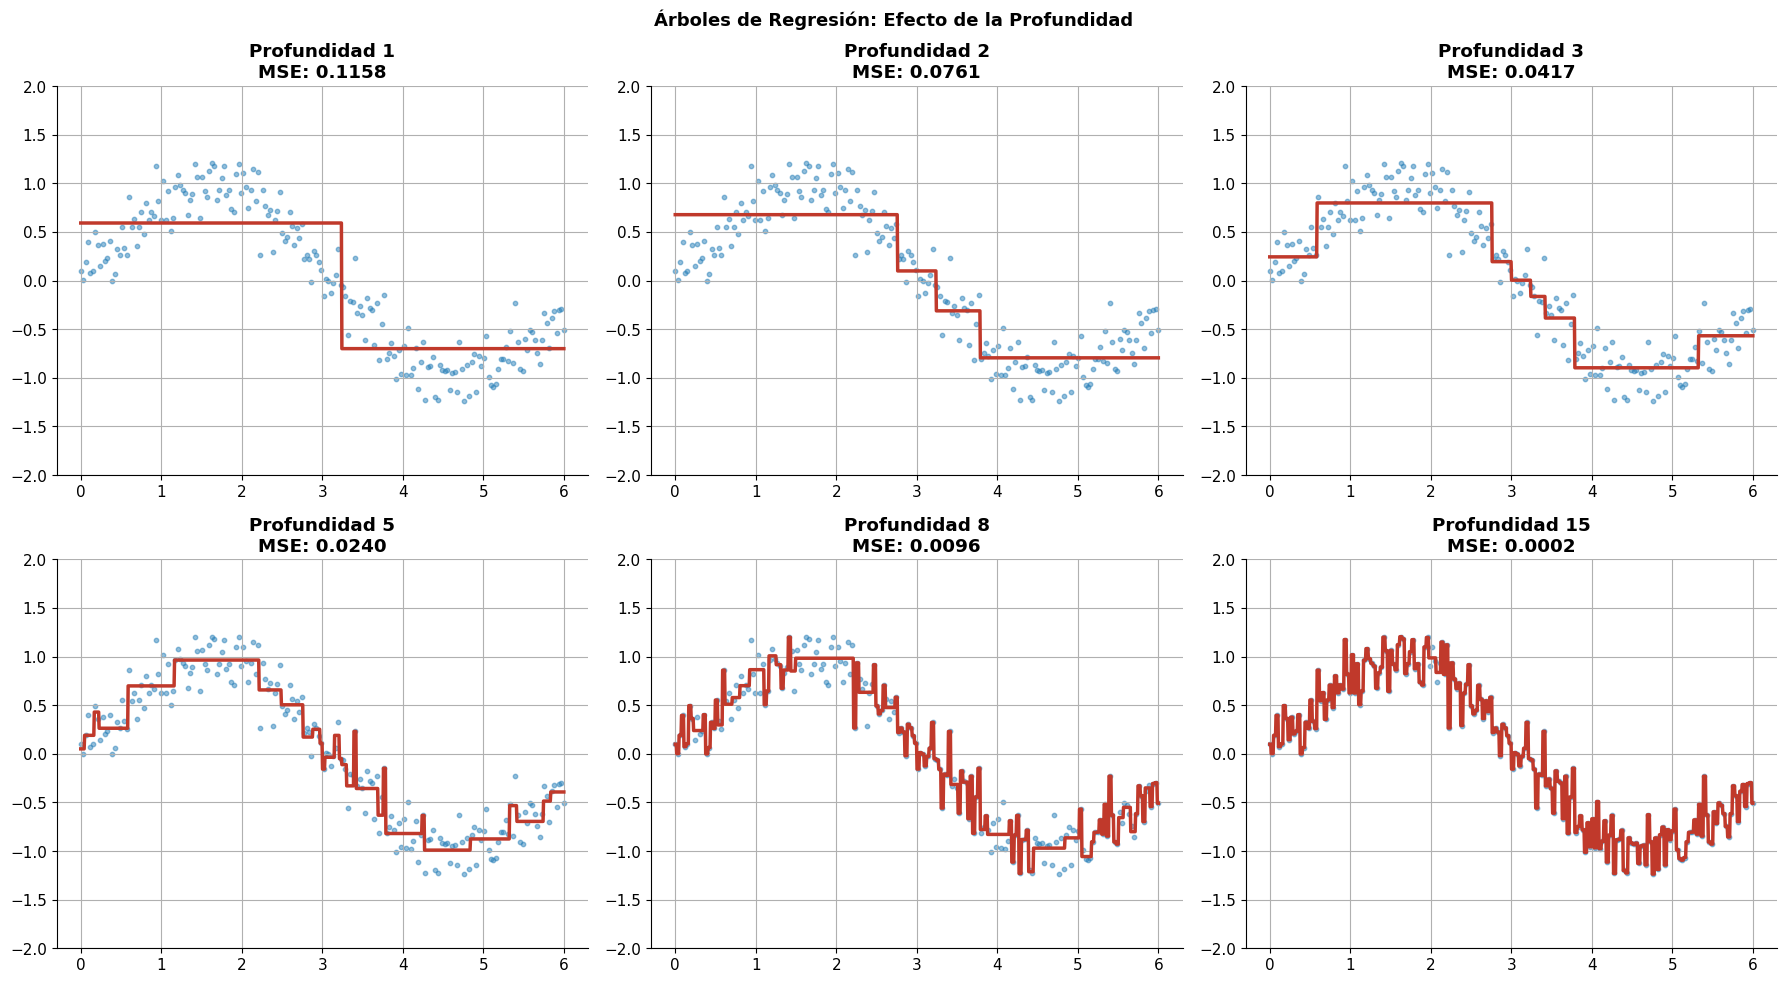

🌳 Observaciones:
   - Profundidad 1-2: sobreajuste por subajuste (líneas rectas)
   - Profundidad 3-5: buen balance, captura la forma sinusoidal
   - Profundidad 8-15: sobreajuste, memoriza el ruido


In [11]:
# Ejemplo de árbol de regresión: ajustar y = sin(x) + ruido
np.random.seed(42)
X_reg = np.linspace(0, 6, 200).reshape(-1, 1)
y_reg = np.sin(X_reg).ravel() + np.random.normal(0, 0.2, 200)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
profundidades = [1, 2, 3, 5, 8, 15]

for ax, d in zip(axes.ravel(), profundidades):
    tree_reg = DecisionTreeRegressor(max_depth=d, random_state=42)
    tree_reg.fit(X_reg, y_reg)
    
    X_plot = np.linspace(0, 6, 1000).reshape(-1, 1)
    y_plot = tree_reg.predict(X_plot)
    
    ax.scatter(X_reg, y_reg, s=10, color='#2980B9', alpha=0.5)
    ax.plot(X_plot, y_plot, color='#C0392B', linewidth=2.5)
    ax.set_title(f'Profundidad {d}\nMSE: {np.mean((y_reg - tree_reg.predict(X_reg))**2):.4f}',
                 fontweight='bold')
    ax.set_ylim(-2, 2)

plt.suptitle('Árboles de Regresión: Efecto de la Profundidad', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print("🌳 Observaciones:")
print("   - Profundidad 1-2: sobreajuste por subajuste (líneas rectas)")
print("   - Profundidad 3-5: buen balance, captura la forma sinusoidal")
print("   - Profundidad 8-15: sobreajuste, memoriza el ruido")

---
# Parte 7: Interpretación

## 7.1 Importancia de Características

La **importancia** de una característica mide su contribución a la reducción de impureza. Para la característica $j$:

$$\boxed{\text{Importance}(j) = \sum_{t \in \text{nodos que dividen por } j} \frac{n_t}{n} \cdot \Delta I(t)}$$

donde $\Delta I(t)$ es la reducción de impureza en el nodo $t$. Las importancias se normalizan para sumar 1:

$$\sum_{j=1}^{d} \text{Importance}(j) = 1$$

## 7.2 Limitaciones de la importancia por impureza

1. **Sesgo hacia variables con más valores:** variables con muchas categorías pueden inflarse artificialmente
2. **Correlación:** si dos variables están correlacionadas, la importancia se reparte entre ellas
3. **Alternativas:** Permutation Importance, SHAP values

## 7.3 Extracción de reglas

Cada camino desde la raíz a una hoja produce una **regla de decisión**:

$$\text{SI } x_{j_1} \le s_1 \land x_{j_2} > s_2 \land \ldots \text{ ENTONCES } \hat{y} = c_t$$

Las reglas son **disjuntas** y **exhaustivas** (cubren todo el espacio).

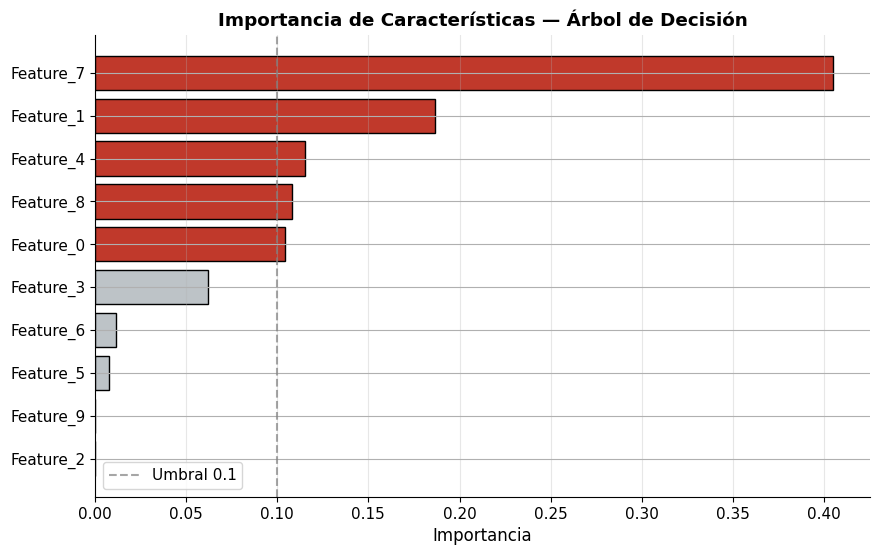

📊 IMPORTANCIA DE CARACTERÍSTICAS
  Feature  Importance
Feature_7    0.404953
Feature_1    0.186829
Feature_4    0.115195
Feature_8    0.107952
Feature_0    0.104183
Feature_3    0.061929
Feature_6    0.011375
Feature_5    0.007583
Feature_9    0.000000
Feature_2    0.000000

💡 Suma de importancias: 1.0000


In [12]:
# Importancia de características en un dataset con features correlacionadas
from sklearn.datasets import make_classification

X_imp, y_imp = make_classification(
    n_samples=500, n_features=10, n_informative=4,
    n_redundant=3, n_classes=2, random_state=42
)
feature_names = [f'Feature_{i}' for i in range(10)]

X_tr_i, X_te_i, y_tr_i, y_te_i = train_test_split(X_imp, y_imp, test_size=0.3, random_state=42)

tree_imp = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_imp.fit(X_tr_i, y_tr_i)

importancias = pd.DataFrame({
    'Feature': feature_names,
    'Importance': tree_imp.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 6))
colors = ['#C0392B' if imp > 0.1 else '#BDC3C7' for imp in importancias['Importance']]
plt.barh(importancias['Feature'], importancias['Importance'], color=colors, edgecolor='k')
plt.xlabel('Importancia', fontsize=12)
plt.title('Importancia de Características — Árbol de Decisión', fontweight='bold')
plt.axvline(x=0.1, color='gray', linestyle='--', alpha=0.7, label='Umbral 0.1')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.show()

print("="*80)
print("📊 IMPORTANCIA DE CARACTERÍSTICAS")
print("="*80)
print(importancias.sort_values('Importance', ascending=False).to_string(index=False))
print(f"\n💡 Suma de importancias: {importancias['Importance'].sum():.4f}")

---
# Parte 8: Resumen y Referencias

## 8.1 Resumen de Ecuaciones Clave

| Concepto | Ecuación |
|----------|----------|
| **Gini** | $I(t) = 1 - \sum_k p_k^2$ |
| **Entropía** | $I(t) = -\sum_k p_k \log_2 p_k$ |
| **Error clasif.** | $I(t) = 1 - \max_k p_k$ |
| **Varianza (regresión)** | $I(t) = \frac{1}{n_t} \sum_i (y_i - \bar{y}_t)^2$ |
| **Ganancia de info.** | $\text{Gain} = I(D) - \sum_v \frac{|D_v|}{|D|} I(D_v)$ |
| **Gain Ratio** | $\text{GainRatio} = \frac{\text{Gain}}{\text{SplitInfo}}$ |
| **Costo CCP** | $R_\alpha(T) = R(T) + \alpha |T|$ |
| **Importancia** | $\text{Imp}(j) = \sum_{t \text{ con } j} \frac{n_t}{n} \Delta I(t)$ |

## 8.2 Cuándo usar Árboles de Decisión

**Usar árboles cuando:**
- Necesitas **interpretabilidad** (reglas explícitas)
- Los datos tienen **variables mixtas** (numéricas + categóricas)
- No quieres escalar los datos
- Tienes suficiente data para validar
- Sirven como **baseline** para métodos más complejos

**No usar árboles cuando:**
- Necesitas **alta precisión** (usar Random Forest o Boosting)
- Las fronteras son **suaves y diagonales** (usar SVM o redes neuronales)
- Hay **alta dimensionalidad** con muchas features irrelevantes

## 8.3 Referencias bibliográficas completas

### Fundacionales
1. **Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984).** *Classification and Regression Trees*. Wadsworth & Brooks/Cole. [CART original]
2. **Quinlan, J. R. (1986).** Induction of Decision Trees. *Machine Learning*, 1(1), 81-106. [ID3]
3. **Quinlan, J. R. (1993).** *C4.5: Programs for Machine Learning*. Morgan Kaufmann. [C4.5 con Gain Ratio]
4. **Shannon, C. E. (1948).** A Mathematical Theory of Communication. *Bell System Technical Journal*, 27, 379-423. [Entropía]
5. **Hyafil, L., & Rivest, R. L. (1976).** Constructing Optimal Binary Decision Trees is NP-Complete. *Information Processing Letters*, 5(1), 15-17.

### Modernas
6. **Hastie, T., Tibshirani, R., & Friedman, J. (2009).** *The Elements of Statistical Learning* (2nd ed.). Springer. Cap. 9. [ESL]
7. **Bishop, C. M. (2006).** *Pattern Recognition and Machine Learning*. Springer. Cap. 14.
8. **Murphy, K. P. (2012).** *Machine Learning: A Probabilistic Perspective*. MIT Press. Cap. 16.
9. **Rokach, L., & Maimon, O. (2005).** Top-down Induction of Decision Trees Classifiers — A Survey. *IEEE Transactions on Systems, Man, and Cybernetics*, 35(4), 476-487.
10. **Kotsiantis, S. B. (2013).** Decision Trees: A Recent Overview. *Artificial Intelligence Review*, 39(4), 261-283.

### Extensiones y aplicaciones
11. **Breiman, L. (2001).** Random Forests. *Machine Learning*, 45(1), 5-32. [Random Forest]
12. **Friedman, J. H. (2001).** Greedy Function Approximation: A Gradient Boosting Machine. *Annals of Statistics*, 29(5), 1189-1232. [Gradient Boosting]
13. **Chen, T., & Guestrin, C. (2016).** XGBoost: A Scalable Tree Boosting System. *KDD 2016*. [XGBoost]
14. **Lundberg, S. M., & Lee, S. I. (2017).** A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*. [SHAP values]

### Documentación de software
15. **Scikit-learn Developers (2024).** *Decision Trees*. https://scikit-learn.org/stable/modules/tree.html
16. **Pedregosa, F., et al. (2011).** Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825-2830.

## 8.4 Ejercicios de Reflexión

### Ejercicio Teórico 1: Demostrar la concavidad de la entropía

Demuestra que $H(p) = -p \log_2 p - (1-p) \log_2 (1-p)$ es cóncava en $[0, 1]$ calculando la segunda derivada.

**Sugerencia:** Usa el hecho de que $\frac{d}{dp} \log_2 p = \frac{1}{p \ln 2}$.

### Ejercicio Teórico 2: Relación entre Gini y Entropía

Demuestra que para $p \in [0, 1]$:

$$\frac{G(p)}{2} \le H(p) \le \log_2(2) \cdot \sqrt{G(p)}$$

**Sugerencia:** Usa la serie de Taylor de $\log_2(1+x)$.

### Ejercicio Teórico 3: Optimalidad del criterio greedy

Explica por qué construir el árbol óptimo global es NP-duro (Hyafil & Rivest, 1976). ¿Bajo qué condiciones el criterio greedy es óptimo?

### Ejercicio Teórico 4: Sensibilidad a la escala

Demuestra que si aplicamos una transformación **monótona creciente** $g$ a una característica $x_j$, el árbol resultante es el mismo (con umbrales transformados). ¿Por qué esto implica que los árboles son **invariantes a escala**?

### Ejercicio Teórico 5: Cost Complexity Pruning

Sea $T_\alpha$ el árbol que minimiza $R_\alpha(T) = R(T) + \alpha |T|$. Demuestra que:

$$R(T_{\alpha_1}) \le R(T_{\alpha_2}) \quad \text{si } \alpha_1 \le \alpha_2$$

Es decir, menor $\alpha$ produce árboles con menor error de clasificación pero mayor complejidad.

In [13]:
# SOLUCIÓN al Ejercicio 1: Demostrar concavidad de la entropía
print("="*80)
print("🔬 SOLUCIÓN Ejercicio 1: Concavidad de la Entropía")
print("="*80)

p = Symbol('p', positive=True)
H = -p * log(p, 2) - (1-p) * log(1-p, 2)

print("\n1. Primera derivada de H(p):")
H_first = sp.simplify(diff(H, p))
display(sp.Eq(Symbol('H\'(p)'), H_first))

print("\n2. Segunda derivada de H(p):")
H_second = sp.simplify(diff(H, p, 2))
display(sp.Eq(Symbol('H\'\'(p)'), H_second))

print("\n3. Análisis del signo de H''(p):")
print("   H''(p) = -1/(p·(1-p)·ln(2))")
print("   Como p ∈ (0,1), entonces p·(1-p) > 0")
print("   Por lo tanto H''(p) < 0 → H es CÓNCAVA ✓")

print("\n4. Evaluación numérica:")
for p_val in [0.1, 0.3, 0.5, 0.7, 0.9]:
    H_second_val = H_second.subs(p, Rational(p_val * 10, 10))
    print(f"   H''({p_val}) = {float(H_second_val):.4f} < 0")

🔬 SOLUCIÓN Ejercicio 1: Concavidad de la Entropía

1. Primera derivada de H(p):


           ⎛1 - p⎞
        log⎜─────⎟
           ⎝  p  ⎠
H'(p) = ──────────
          log(2)  


2. Segunda derivada de H(p):


                1        
H''(p) = ────────────────
         p⋅(p - 1)⋅log(2)


3. Análisis del signo de H''(p):
   H''(p) = -1/(p·(1-p)·ln(2))
   Como p ∈ (0,1), entonces p·(1-p) > 0
   Por lo tanto H''(p) < 0 → H es CÓNCAVA ✓

4. Evaluación numérica:
   H''(0.1) = -16.0299 < 0
   H''(0.3) = -6.8700 < 0
   H''(0.5) = -5.7708 < 0
   H''(0.7) = -6.8700 < 0
   H''(0.9) = -16.0299 < 0


🔬 SOLUCIÓN Ejercicio 2: Relación Gini-Entropía

Verificación numérica de: G(p)/2 ≤ H(p) ≤ log₂(2)·√G(p)

Cota inferior se cumple: True
Cota superior se cumple: False


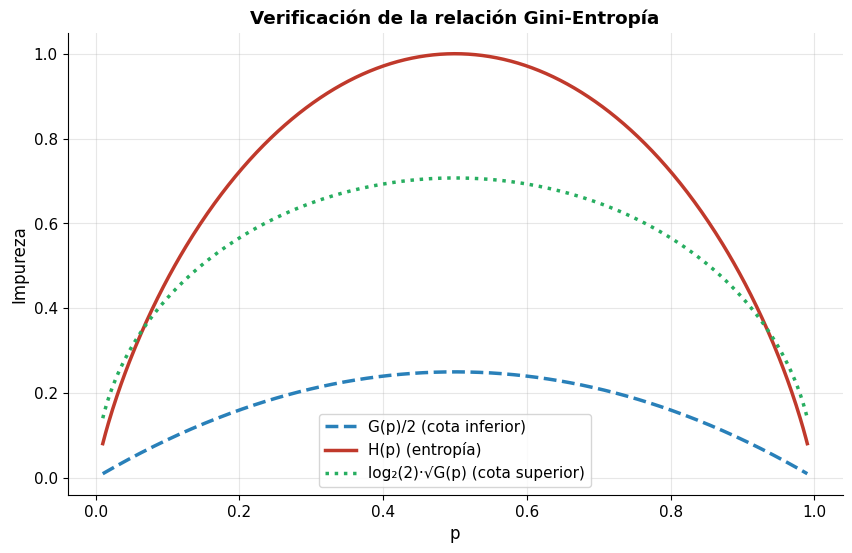

In [14]:
# SOLUCIÓN al Ejercicio 2: Verificación de la desigualdad Gini-Entropía
print("="*80)
print("🔬 SOLUCIÓN Ejercicio 2: Relación Gini-Entropía")
print("="*80)

p_vals = np.linspace(0.01, 0.99, 500)
g = 1 - p_vals**2 - (1-p_vals)**2
h = -p_vals * np.log2(p_vals) - (1-p_vals) * np.log2(1-p_vals)

# Cotas
cota_inferior = g / 2
cota_superior = np.log2(2) * np.sqrt(g)

print("\nVerificación numérica de: G(p)/2 ≤ H(p) ≤ log₂(2)·√G(p)")
print(f"\nCota inferior se cumple: {np.all(h >= cota_inferior - 1e-10)}")
print(f"Cota superior se cumple: {np.all(h <= cota_superior + 1e-10)}")

# Visualización
plt.figure(figsize=(10, 6))
plt.plot(p_vals, g/2, '--', color='#2980B9', linewidth=2.5, label='G(p)/2 (cota inferior)')
plt.plot(p_vals, h, '-', color='#C0392B', linewidth=2.5, label='H(p) (entropía)')
plt.plot(p_vals, np.log2(2)*np.sqrt(g), ':', color='#27AE60', linewidth=2.5, label='log₂(2)·√G(p) (cota superior)')
plt.xlabel('p', fontsize=12)
plt.ylabel('Impureza', fontsize=12)
plt.title('Verificación de la relación Gini-Entropía', fontweight='bold')
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.show()

## 8.5 Conclusiones Finales

### Ideas clave

1. **Los árboles son modelos de partición recursiva:** dividen el espacio en regiones rectangulares ortogonales
2. **La impureza guía la construcción:** Gini y Entropía son las métricas más comunes; son suaves y bien comportadas
3. **La construcción es greedy:** el óptimo global es NP-duro, por lo que CART usa divisiones locales óptimas
4. **La poda es esencial:** sin ella, los árboles sobreajustan severamente
5. **CCP balancea complejidad y precisión:** el parámetro $\alpha$ controla el trade-off de forma teórica-principiada
6. **Los árboles son interpretables:** las reglas extraídas son directamente utilizables por expertos de dominio

### Mensaje pedagógico

Los árboles de decisión son el **punto de partida ideal** para el aprendizaje supervisado porque:
- Su construcción es intuitiva (particiones sucesivas)
- Sus predicciones son explicables (reglas "si-entonces")
- Sirven de base para métodos más potentes (Random Forest, XGBoost, LightGBM)

En la próxima práctica aplicaremos estos conceptos a un **dataset sintético** para experimentar sin distracciones, y luego a los **datos de rendimiento académico** para resolver un problema real.